# 01 · Dataset overview and eigenimages

This notebook introduces the data and the first unsupervised view of it:
a **principal component analysis (PCA) of the raw pixels**, whose components
can be displayed as images ("eigenimages", as in the classic *eigenfaces*).

**Data.** One 2D tau-PET slice per subject and per anatomical view (axial,
coronal, sagittal), for three diagnostic groups: cognitively normal (CN),
mild cognitive impairment (MCI) and Alzheimer's disease (AD). Images are
grayscale PNGs normalised to [0, 1]; brighter means more tau tracer uptake.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.linalg import svd

from adni_tau.data import ImageLoader
from adni_tau.paths import save_figure, save_table
from adni_tau.roi import brain_mask

plt.rcParams["figure.dpi"] = 90
VIEWS = ["axial", "coronal", "sagittal"]
CLASSES = ["CN", "MCI", "AD"]

loader = ImageLoader(views=VIEWS, classes=CLASSES)

## 1. Class balance

The dataset is strongly imbalanced: AD subjects are about 10% of the total.
This drives several later choices (balanced accuracy as the main metric,
class weights, and a balanced subset for the TDA experiments).

In [2]:
counts = pd.DataFrame(
    {view: [len(loader.get_indices(views=[view], classes=[c])) for c in CLASSES] for view in VIEWS},
    index=CLASSES,
)
counts.loc["total"] = counts.sum()
save_table(counts, "dataset_counts", index=True)
counts

,axial,coronal,sagittal
CN,631,631,631
MCI,356,356,356
AD,106,106,106
total,1093,1093,1093


## 2. What the images look like

Class-average images per view. AD subjects show visibly higher tracer uptake
in temporal and parietal cortex, the classic Braak-stage pattern of tau
spreading; MCI sits in between.

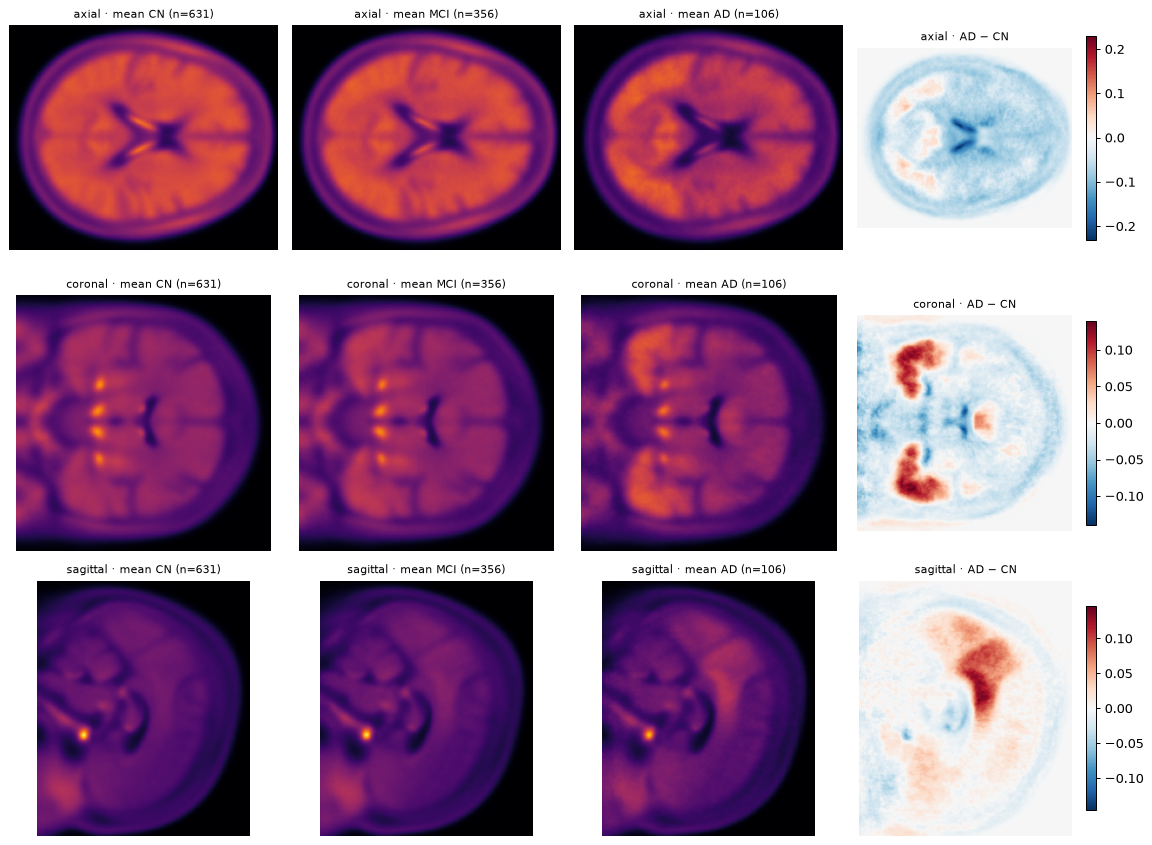

In [3]:
data = {view: loader.load_view(view) for view in VIEWS}

fig, axes = plt.subplots(len(VIEWS), len(CLASSES) + 1, figsize=(13, 9.5))
for r, view in enumerate(VIEWS):
    d = data[view]
    means = {c: d["X"][d["classes"] == c].mean(axis=0).reshape(d["shape"]) for c in CLASSES}
    for ax, c in zip(axes[r], CLASSES):
        ax.imshow(means[c], cmap="inferno", vmin=0, vmax=0.8)
        ax.set_title(f"{view} · mean {c} (n={np.sum(d['classes'] == c)})", fontsize=9)
        ax.axis("off")
    diff = means["AD"] - means["CN"]
    lim = np.abs(diff).max()
    im = axes[r, -1].imshow(diff, cmap="RdBu_r", vmin=-lim, vmax=lim)
    axes[r, -1].set_title(f"{view} · AD − CN", fontsize=9)
    axes[r, -1].axis("off")
    fig.colorbar(im, ax=axes[r, -1], shrink=0.8)
fig.tight_layout()
save_figure(fig, "01_class_mean_images")

## 3. PCA of the pixels (eigenimages)

For each view we stack the images as rows of a matrix
$X \in \mathbb{R}^{n \times p}$ ($p$ = number of pixels). Background pixels
carry no information, so we first restrict the analysis to a **brain mask**:
pixels whose intensity is above 0.02 in at least 70% of the images.

After centring, the SVD $X_c = U S V^\top$ gives the principal directions as
the rows of $V^\top$. Reshaped to the image grid, each one is an eigenimage:
red and blue regions vary in opposite directions along that component.

In [4]:
pca_by_view = {}
for view in VIEWS:
    d = data[view]
    mask = brain_mask(d["X"], d["shape"]).reshape(-1) == 1
    Xc = d["X"][:, mask] - d["X"][:, mask].mean(axis=0)
    U, s, Vt = svd(Xc, full_matrices=False)
    eig = np.zeros((10, mask.size))
    eig[:, mask] = Vt[:10]
    pca_by_view[view] = {
        "eigenimages": eig.reshape(10, *d["shape"]),
        "scores": U[:, :10] * s[:10],
        "explained": s**2 / np.sum(s**2),
        "mask": mask.reshape(d["shape"]),
    }
    print(f"{view:>8}: {mask.sum():>5} brain pixels, first 10 PCs explain {pca_by_view[view]['explained'][:10].sum():.1%} of the variance")

   axial: 28381 brain pixels, first 10 PCs explain 71.9% of the variance


 coronal: 26256 brain pixels, first 10 PCs explain 62.5% of the variance


sagittal: 31375 brain pixels, first 10 PCs explain 58.2% of the variance


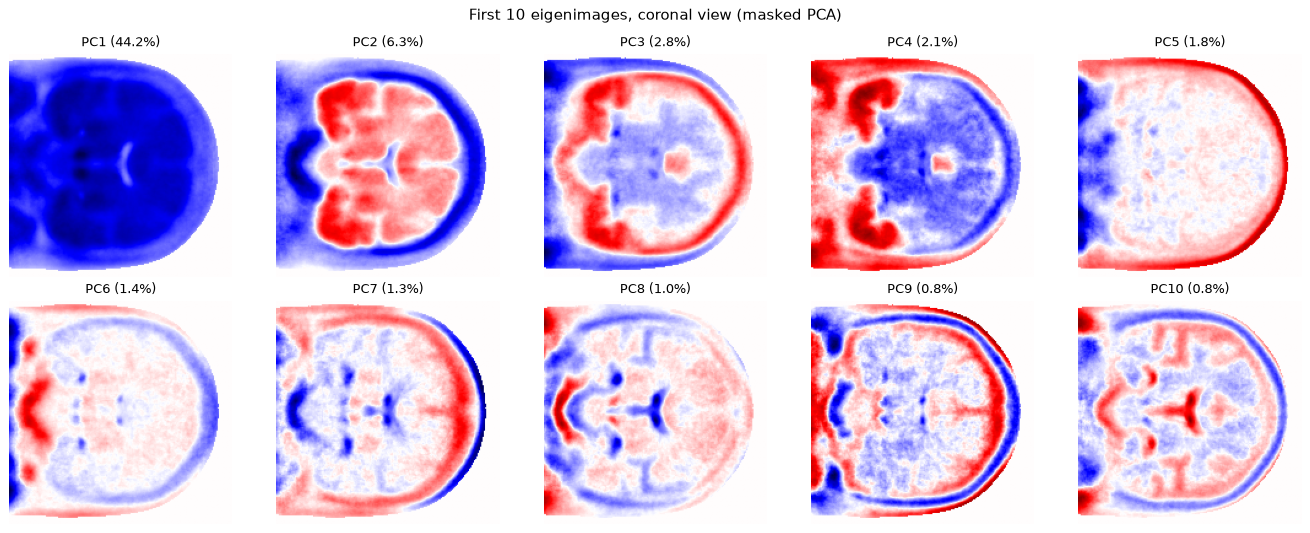

In [5]:
view = "coronal"
p = pca_by_view[view]
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for i, ax in enumerate(axes.ravel()):
    lim = np.abs(p["eigenimages"][i]).max()
    ax.imshow(p["eigenimages"][i], cmap="seismic", vmin=-lim, vmax=lim)
    ax.set_title(f"PC{i + 1} ({p['explained'][i]:.1%})", fontsize=10)
    ax.axis("off")
fig.suptitle(f"First 10 eigenimages, {view} view (masked PCA)")
fig.tight_layout()
save_figure(fig, "01_eigenimages_coronal")

**Reading the eigenimages.** PC1 is almost uniform in sign: it captures the
overall brightness of a scan (global uptake and scanner normalisation), not
a localised pattern. Later components contrast specific regions, e.g. cortex
against white matter, or one lobe against another.

## 4. Do the classes separate along the leading components?

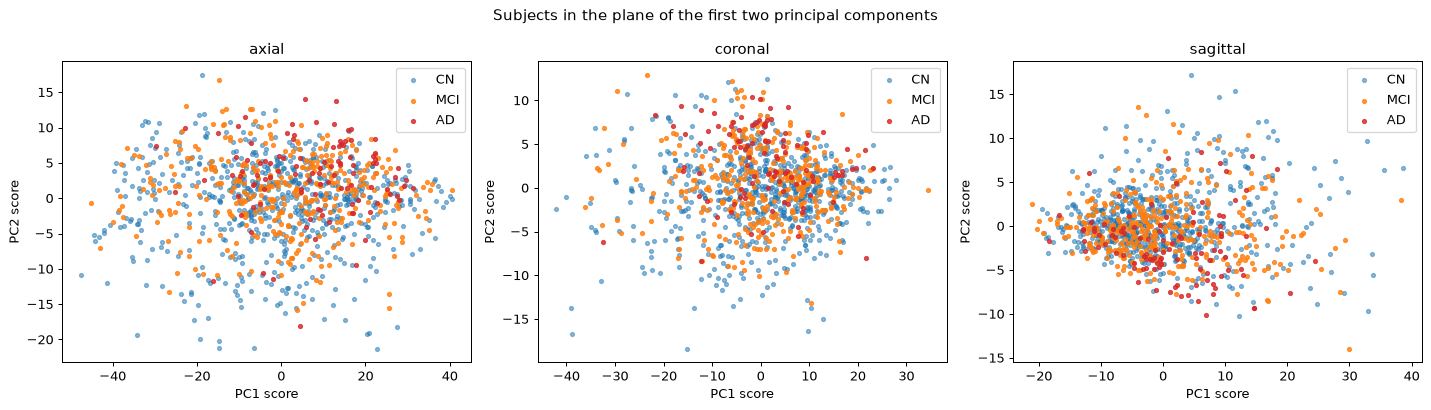

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
colors = {"CN": "tab:blue", "MCI": "tab:orange", "AD": "tab:red"}
for ax, view in zip(axes, VIEWS):
    sc, cls = pca_by_view[view]["scores"], data[view]["classes"]
    for c in CLASSES:
        m = cls == c
        ax.scatter(sc[m, 0], sc[m, 1], s=10, alpha=0.5 if c == "CN" else 0.8, color=colors[c], label=c)
    ax.set(title=view, xlabel="PC1 score", ylabel="PC2 score")
    ax.legend()
fig.suptitle("Subjects in the plane of the first two principal components")
fig.tight_layout()
save_figure(fig, "01_pc1_pc2_scatter")

The groups overlap heavily in the PC1–PC2 plane. AD subjects drift towards
one side, but the directions of **largest variance** are not necessarily the
directions that **separate the diagnoses**. Notebook 02 addresses this by
testing every component for group differences and keeping only the
discriminative ones.